# Comparing structural features to confidence scores

In [1]:
import warnings
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import statsmodels.api as sm
from matplotlib import patches
from matplotlib.ticker import PercentFormatter

In [2]:
SIGNIFICANCE_LEVEL = 0.05

In [3]:
entries = pd.read_csv('../data/interim/sequences_sample_1500.csv')

In [4]:
entries['type'] = entries['label'].map(lambda label: 'binder' if label else 'decoy')

In [5]:
confidence_scores = pd.read_csv('../data/processed/confidence_scores_af3_af3_tcrmodel2_1500.csv')
af3_structural_features = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_structural_features_1500.csv')

structure_scores = entries.merge(
    confidence_scores,
    how='left',
    left_on='index',
    right_on='structure_name',
).merge(
    af3_structural_features,
    how='inner',
    left_on=['index', 'sample', 'seed'],
    right_on=['name', 'sample', 'seed'],
)

## Probabilities for structural features

In [6]:
structural_features = pd.read_csv('../data/processed/tcr_pmhc_structural_features.csv')

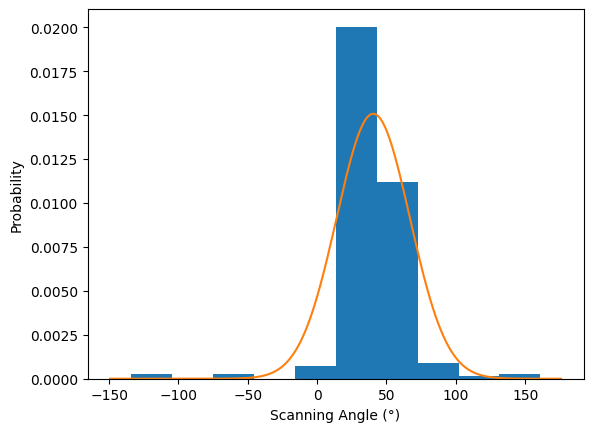

In [7]:
loc, scale = scipy.stats.norm.fit(structural_features['scanning_angle'])
scanning_angle = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['scanning_angle'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = scanning_angle.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Scanning Angle (°)')
plt.ylabel('Probability')

plt.show()

In [8]:
structure_scores['scanning_angle_probability'] = structure_scores['scanning_angle'].apply(scanning_angle.pdf)

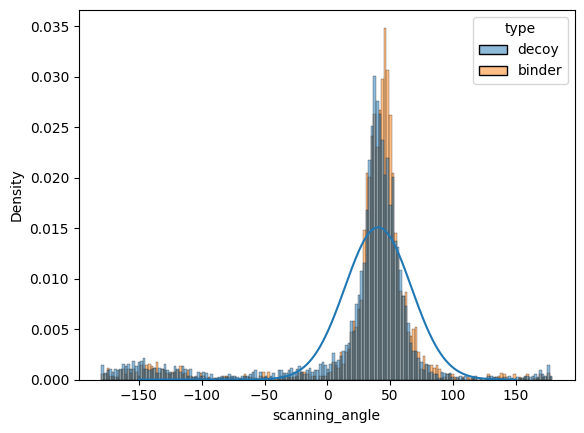

In [9]:
x = np.linspace(-150, 150, 1000)
plt.plot(x, scanning_angle.pdf(x))

sns.histplot(structure_scores, hue='type', x='scanning_angle', stat='density', common_norm=False)

plt.show()

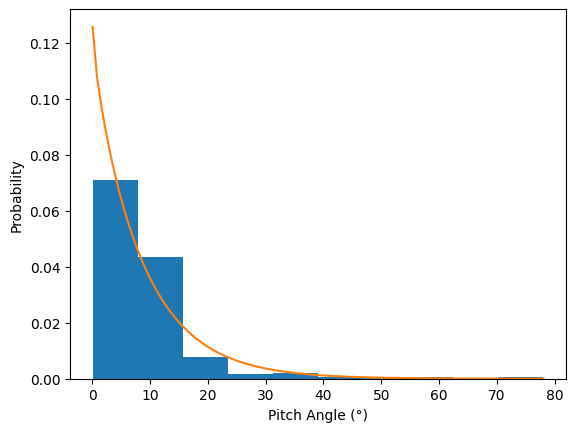

In [10]:
a, loc, scale = scipy.stats.gamma.fit(structural_features['pitch_angle'], floc=0)
pitch_angle = scipy.stats.gamma(a=a, loc=loc, scale=scale)

ax = structural_features['pitch_angle'].plot.hist(density=True)

x = np.linspace(structural_features['pitch_angle'].min(), structural_features['pitch_angle'].max(), 100)
y = pitch_angle.pdf(x)

plt.plot(x, y, '-')


plt.xlabel('Pitch Angle (°)')
plt.ylabel('Probability')

plt.show()

In [11]:
structure_scores['pitch_angle_probability'] = structure_scores['pitch_angle'].apply(pitch_angle.pdf).replace(np.inf, 1)

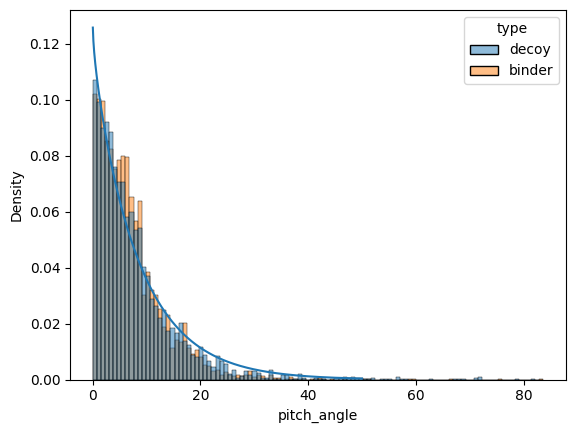

In [12]:
x = np.linspace(0, 50, 1000)
plt.plot(x, pitch_angle.pdf(x))

sns.histplot(structure_scores, x='pitch_angle', hue='type', stat='density', common_norm=False)

plt.show()

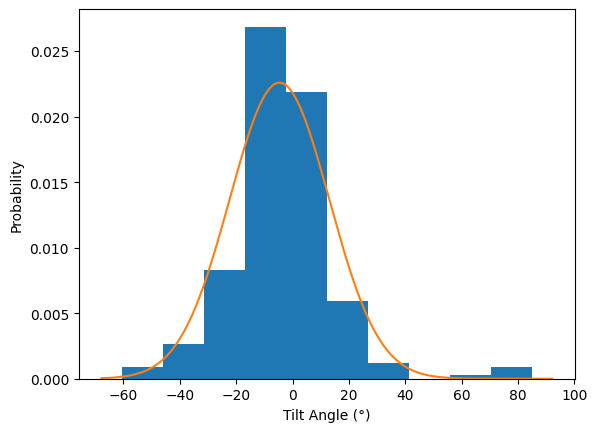

In [13]:
loc, scale = scipy.stats.norm.fit(structural_features['tilt_angle'])
tilt_angle = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['tilt_angle'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = tilt_angle.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Tilt Angle (°)')
plt.ylabel('Probability')

plt.show()

In [14]:
structure_scores['tilt_angle_probability'] = structure_scores['tilt_angle'].apply(tilt_angle.pdf)

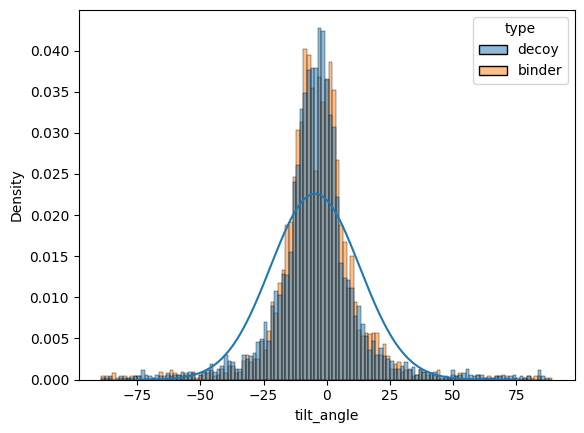

In [15]:
x = np.linspace(-75, 75, 1000)
plt.plot(x, tilt_angle.pdf(x))

sns.histplot(structure_scores, x='tilt_angle', hue='type', stat='density', common_norm=False)

plt.show()

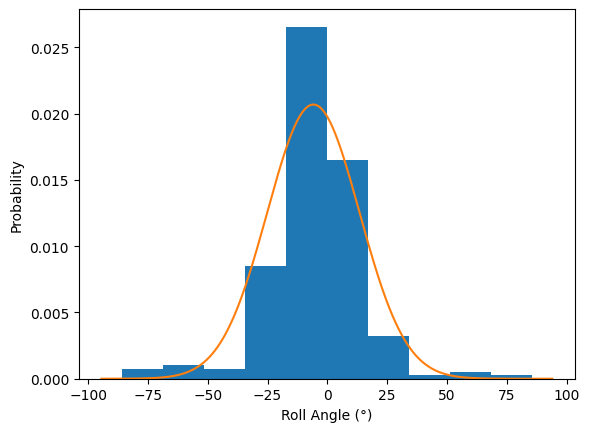

In [16]:
loc, scale = scipy.stats.norm.fit(structural_features['roll_angle'])
roll_angle = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['roll_angle'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = roll_angle.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Roll Angle (°)')
plt.ylabel('Probability')

plt.show()

In [17]:
structure_scores['roll_angle_probability'] = structure_scores['roll_angle'].apply(roll_angle.pdf)

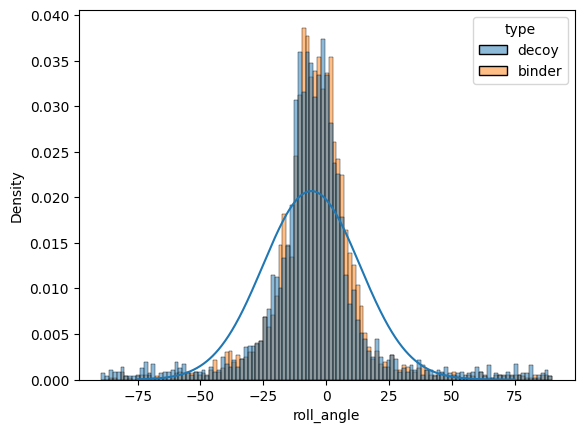

In [18]:
x = np.linspace(-75, 75, 1000)
plt.plot(x, roll_angle.pdf(x))

sns.histplot(structure_scores, x='roll_angle', hue='type', stat='density', common_norm=False)

plt.show()

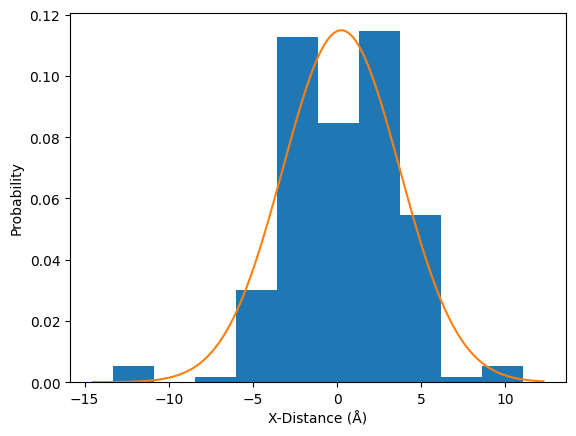

In [19]:
loc, scale = scipy.stats.norm.fit(structural_features['x_score'])
x_score = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['x_score'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = x_score.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('X-Distance (Å)')
plt.ylabel('Probability')

plt.show()

In [20]:
structure_scores['x_score_probability'] = structure_scores['x_score'].apply(x_score.pdf)

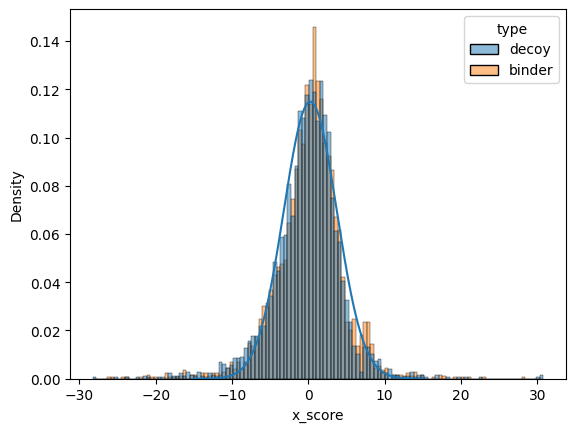

In [21]:
x = np.linspace(-15, 15, 1000)
plt.plot(x, x_score.pdf(x))

sns.histplot(structure_scores, x='x_score', hue='type', stat='density', common_norm=False)

plt.show()

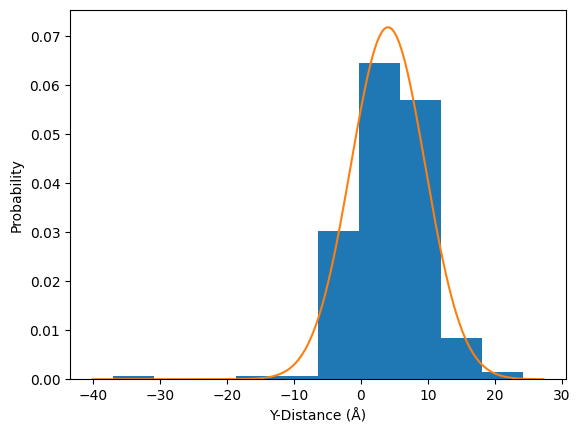

In [22]:
loc, scale = scipy.stats.norm.fit(structural_features['y_score'])
y_score = scipy.stats.norm(loc=loc, scale=scale)

ax = structural_features['y_score'].plot.hist(density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = y_score.pdf(x)

plt.plot(x, y, '-')

plt.xlabel('Y-Distance (Å)')
plt.ylabel('Probability')

plt.show()

In [23]:
structure_scores['y_score_probability'] = structure_scores['y_score'].apply(y_score.pdf)

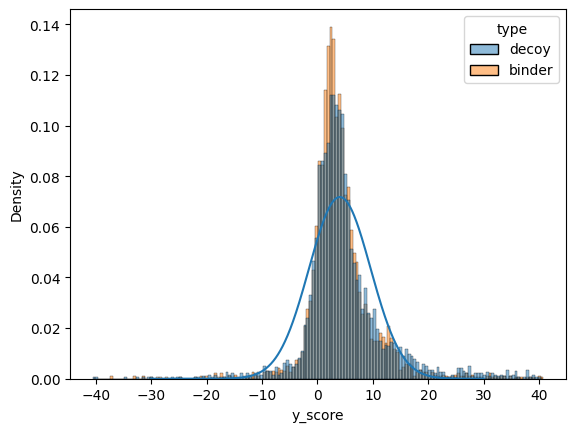

In [24]:
x = np.linspace(-30, 30, 1000)
plt.plot(x, y_score.pdf(x))

sns.histplot(structure_scores, x='y_score', hue='type', stat='density', common_norm=False)

plt.show()

In [25]:
def z_score(x: float | np.ndarray, means: np.ndarray, variances: np.ndarray, weights: np.ndarray) -> float | np.ndarray:
    pdfs = [
        w * scipy.stats.norm.pdf(x, loc=mu, scale=np.sqrt(var))
        for w, mu, var in zip(weights, means, variances, strict=True)
    ]

    return np.sum(pdfs, axis=0)

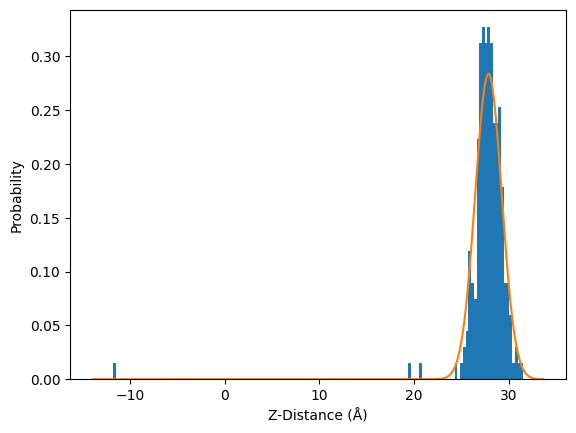

In [26]:
gmm = sklearn.mixture.GaussianMixture(n_components=2)
gmm.fit(structural_features['z_score'].to_numpy().reshape(-1, 1))

ax = structural_features['z_score'].plot.hist(bins=150, density=True)

x = np.linspace(*ax.get_xlim(), 1000)
y = z_score(x, gmm.means_.flatten(), gmm.covariances_.flatten(), gmm.weights_.flatten())

plt.plot(x, y, '-')

plt.xlabel('Z-Distance (Å)')
plt.ylabel('Probability')

plt.show()

In [27]:
structure_scores['z_score_probability'] = structure_scores['z_score'].apply(
    z_score, means=gmm.means_.flatten(), variances=gmm.covariances_.flatten(), weights=gmm.weights_.flatten()
)

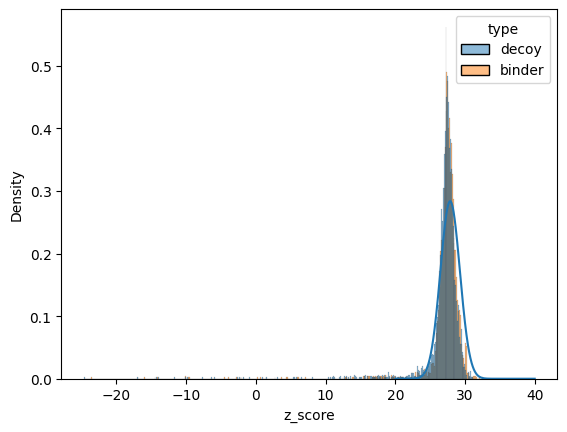

In [28]:
x = np.linspace(20, 40, 1000)
plt.plot(x, z_score(x, gmm.means_.flatten(), gmm.covariances_.flatten(), gmm.weights_.flatten()))

sns.histplot(structure_scores, x='z_score', hue='type', stat='density', common_norm=False)

plt.show()

In [29]:
contact_probabilities = pd.read_csv('../data/external/tcr_pmhc_contacts.csv')

contact_probabilities['proportion'] = contact_probabilities.groupby('mhc_type')['proportion'].transform(
    lambda group: group / group.sum()
)

contact_maps = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_contact_maps_1500.csv')

contact_scores = (
    contact_maps.merge(
        contact_probabilities,
        how='left',
        on=[col for col in contact_probabilities if col != 'proportion'],
    )
    .groupby(['name', 'seed', 'sample'])['proportion']
    .aggregate(['sum', 'mean'])
)
contact_scores.columns = ['contact_map_probability_' + column_name for column_name in contact_scores.columns]

structure_scores = structure_scores.merge(
    contact_scores, how='left', left_on=['name', 'seed', 'sample'], right_index=True
)

<Axes: xlabel='score', ylabel='probability'>

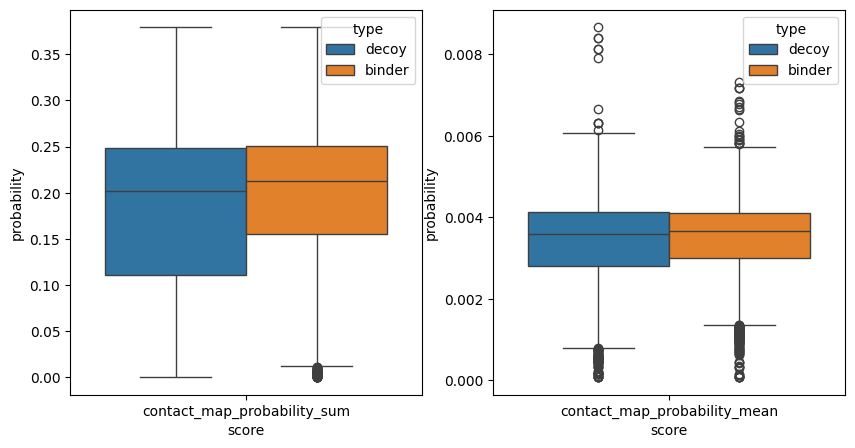

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_sum',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[0],
)

sns.boxplot(
    structure_scores.melt(
        id_vars=['type', 'label'],
        value_vars='contact_map_probability_mean',
        var_name='score',
        value_name='probability',
    ),
    x='score',
    y='probability',
    hue='type',
    ax=axes[1],
)

In [31]:
structure_scores['contact_map_probability'] = structure_scores['contact_map_probability_mean']

In [32]:
interactions = pd.read_csv('../data/processed/tcr_pmhc_interactions.csv')

In [33]:
num_interactions = interactions.groupby('name').size()

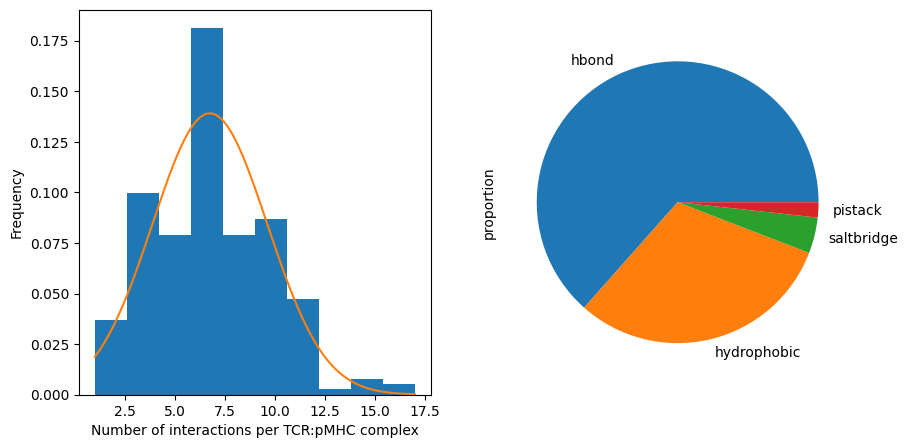

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

num_interactions.plot.hist(ax=axes[0], density=True)
x = np.linspace(num_interactions.min(), num_interactions.max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=num_interactions.std())

axes[0].plot(x, y, '-')

axes[0].set_xlabel('Number of interactions per TCR:pMHC complex')

interactions.value_counts('type', normalize=True).plot.pie(ax=axes[1])

plt.show()

In [35]:
interaction_types = interactions.value_counts(['type', 'name'])

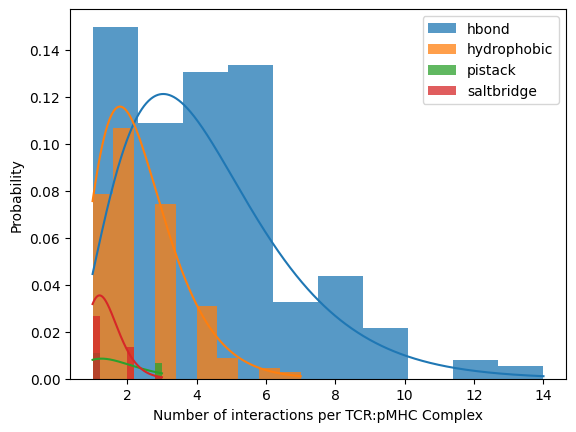

In [36]:
colours = plt.rcParams['axes.prop_cycle'].by_key()['color']

total_count = interaction_types.sum()

interaction_types_parameters = {}

for i, (interaction_type, group) in enumerate(interaction_types.reset_index().groupby('type')):
    interaction_types_parameters[interaction_type] = {}

    colour = colours[i % len(colours)]

    count = group['count']
    group_count = count.sum()

    weight = group_count / total_count

    a, loc, scale = scipy.stats.gamma.fit(group['count'], floc=0)

    interaction_types_parameters[interaction_type]['weight'] = weight
    interaction_types_parameters[interaction_type]['a'] = a
    interaction_types_parameters[interaction_type]['loc'] = loc
    interaction_types_parameters[interaction_type]['scale'] = scale

    x = np.linspace(count.min(), count.max(), 1000)
    y = scipy.stats.gamma.pdf(x, a=a, loc=loc, scale=scale) * weight

    plt.plot(x, y, '-', color=colour)

    counts, bins = np.histogram(count)
    probabilities = (counts / counts.sum()) * weight

    plt.stairs(
        probabilities,
        bins,
        fill=True,
        color=colour,
        alpha=0.75,
        label=interaction_type,
    )

plt.legend()
plt.ylabel('Probability')
plt.xlabel('Number of interactions per TCR:pMHC Complex')
plt.show()

In [37]:
af3_interactions = pd.read_csv('../data/processed/predicted_af3_af3_af3_interactions_50.csv')
af3_interactions = af3_interactions.merge(
    entries, how='left', left_on='name', right_on='index', suffixes=('_interaction', '')
)

ROC-AUC: 0.6427692307692308


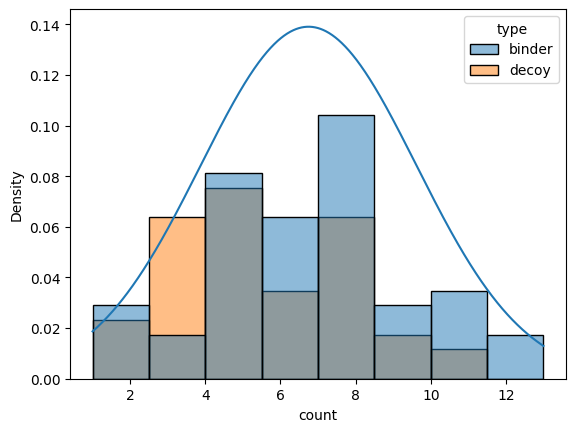

In [38]:
af3_interaction_counts = af3_interactions.groupby(['type', 'label', 'name', 'seed', 'sample']).size()
af3_interaction_counts.name = 'count'
af3_interaction_counts = af3_interaction_counts.reset_index()

sns.histplot(af3_interaction_counts, x='count', hue='type', stat='density')

x = np.linspace(af3_interaction_counts['count'].min(), af3_interaction_counts['count'].max(), 1000)
y = scipy.stats.norm.pdf(x, loc=num_interactions.mean(), scale=num_interactions.std())
plt.plot(x, y, '-')

print('ROC-AUC:', sklearn.metrics.roc_auc_score(af3_interaction_counts['label'], af3_interaction_counts['count']))

plt.show()

In [39]:
af3_interaction_counts['num_interactions_probability'] = scipy.stats.norm.pdf(
    af3_interaction_counts['count'], loc=num_interactions.mean(), scale=num_interactions.std()
)
structure_scores = structure_scores.merge(
    af3_interaction_counts[['name', 'seed', 'sample', 'num_interactions_probability']],
    how='left',
    left_on=['name', 'seed', 'sample'],
    right_on=['name', 'seed', 'sample'],
)
structure_scores['num_interactions_probability'] = structure_scores['num_interactions_probability'].fillna(0.0)

hbond ROC-AUC: 0.652834699453552
hydrophobic ROC-AUC: 0.5290423861852434
pistack ROC-AUC: nan
saltbridge ROC-AUC: 0.4615384615384615


/ceph/project/koohylab/bmcmaste/projects/tcr-pmhc-predicted-structures/.venv/lib/python3.11/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


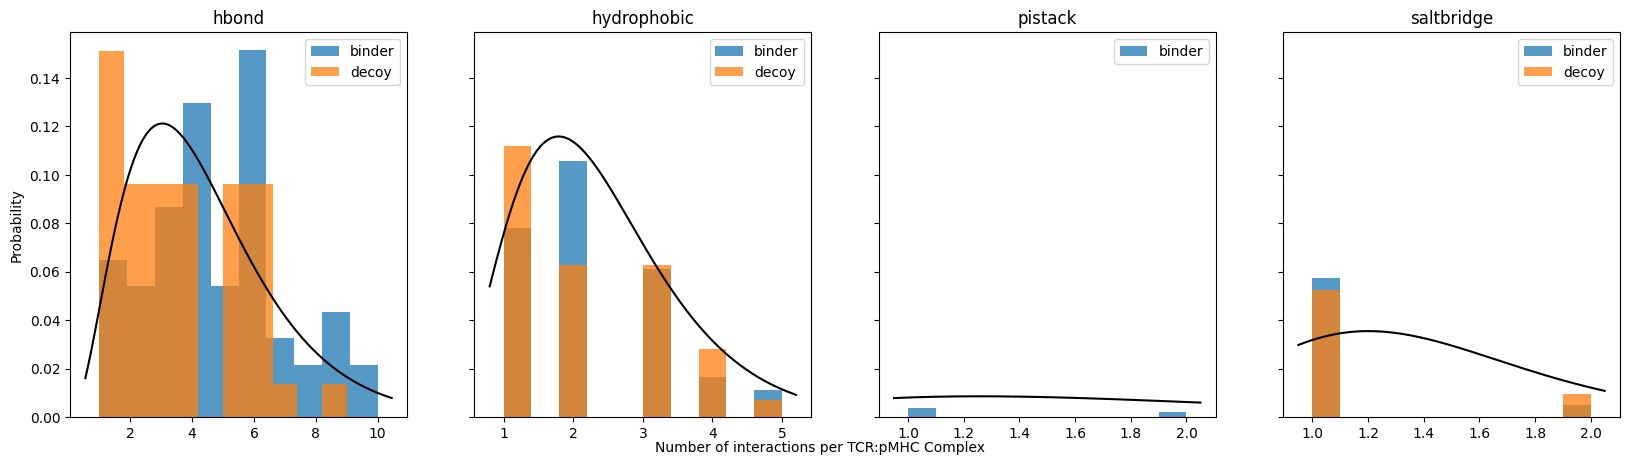

In [40]:
af3_interaction_types = af3_interactions.value_counts(
    ['name', 'seed', 'sample', 'type', 'label', 'type_interaction']
).reset_index()

total_count = af3_interaction_types['count'].sum()

number_of_interaction_types = len(interaction_types_parameters)

fig, axes = plt.subplots(1, number_of_interaction_types, figsize=(5 * number_of_interaction_types, 5), sharey=True)

for i, (interaction_type, group) in enumerate(af3_interaction_types.groupby('type_interaction')):
    group_count = group['count'].sum()

    weight = group_count / total_count

    for complex_type, sub_group in group.groupby('type'):
        counts, bins = np.histogram(sub_group['count'])
        probabilities = (counts / counts.sum()) * weight

        axes[i].stairs(
            probabilities,
            bins,
            fill=True,
            alpha=0.75,
            label=complex_type,
        )

    x = np.linspace(*axes[i].get_xlim(), 1000)
    y = (
        scipy.stats.gamma.pdf(
            x,
            a=interaction_types_parameters[interaction_type]['a'],
            loc=interaction_types_parameters[interaction_type]['loc'],
            scale=interaction_types_parameters[interaction_type]['scale'],
        )
        * interaction_types_parameters[interaction_type]['weight']
    )

    axes[i].plot(x, y, '-', color='black')

    axes[i].set_title(interaction_type)
    axes[i].legend()

    print(interaction_type, 'ROC-AUC:', sklearn.metrics.roc_auc_score(group['label'], group['count']))

axes[0].set_ylabel('Probability')
fig.text(0.5, 0.04, 'Number of interactions per TCR:pMHC Complex', ha='center')

plt.show()

In [41]:
index = pd.MultiIndex.from_frame(structure_scores[['name', 'seed', 'sample']])
probabilities = pd.Series(np.zeros(len(index)), index=index)
probabilities.name = 'interaction_type_probability'
for interaction_type, params in interaction_types_parameters.items():
    interaction_type_counts = af3_interaction_types[
        af3_interaction_types['type_interaction'] == interaction_type
    ].set_index(['name', 'seed', 'sample'])['count']

    interaction_type_probabilities = interaction_type_counts.apply(
        lambda counts, params=params: params['weight']
        * scipy.stats.gamma.pdf(counts, a=params['a'], loc=params['loc'], scale=params['scale']),
    )
    interaction_type_probabilities.name = 'interaction_type_probability'

    probabilities = probabilities.add(interaction_type_probabilities, fill_value=0.0)

structure_scores = structure_scores.merge(probabilities.reset_index(), how='left', on=['name', 'seed', 'sample'])

In [42]:
structure_probability_names = [
    'scanning_angle_probability',
    'pitch_angle_probability',
    'tilt_angle_probability',
    'roll_angle_probability',
    'x_score_probability',
    'y_score_probability',
    'z_score_probability',
    'contact_map_probability',
    'num_interactions_probability',
    'interaction_type_probability',
]

In [43]:
structure_scores = structure_scores.dropna().copy()

In [44]:
with np.errstate(divide='ignore'):
    structure_scores['log_probability'] = structure_scores[structure_probability_names].apply(
        lambda row: np.sum(np.log(row)), axis=1
    )

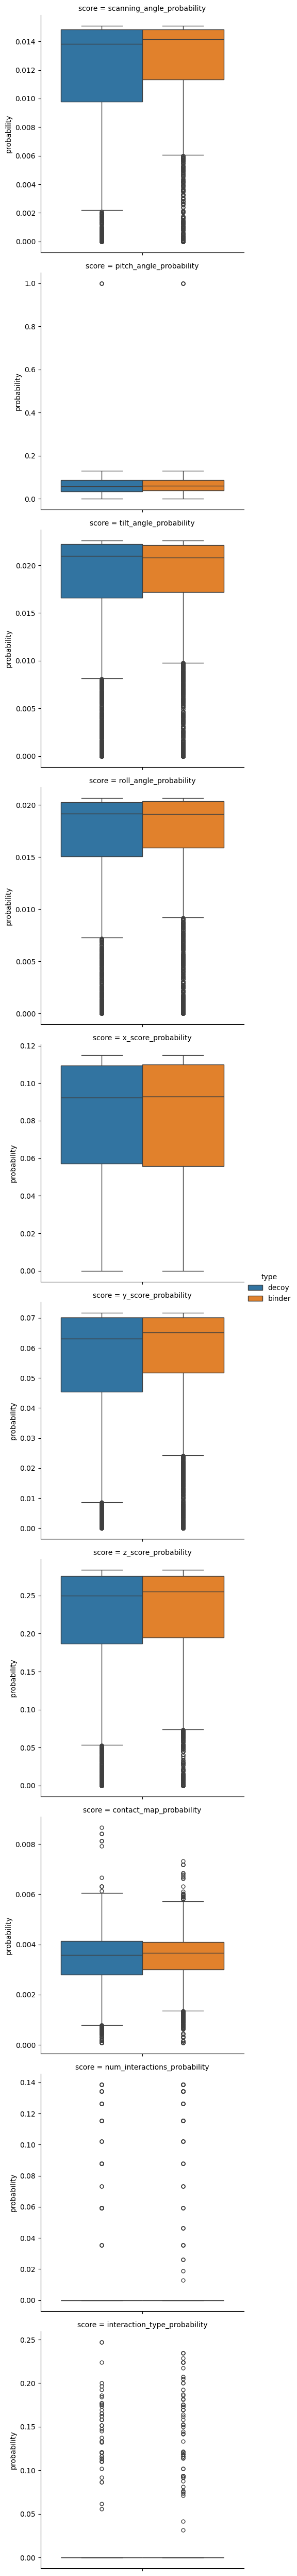

In [45]:
score_probabilities = structure_scores.melt(
    id_vars=['type', 'label'],
    value_vars=structure_probability_names,
    var_name='score',
    value_name='probability',
)
sns.catplot(score_probabilities, row='score', y='probability', hue='type', sharey=False, kind='box')

In [46]:
for score_name, group in score_probabilities.groupby('score'):
    print(score_name)
    print(sklearn.metrics.roc_auc_score(group['label'], group['probability']))

contact_map_probability
0.5239544227328592
interaction_type_probability
0.5020334387044354
num_interactions_probability
0.5020478161824361
pitch_angle_probability
0.5133150154703134
roll_angle_probability
0.5131832280504817
scanning_angle_probability
0.5293892932723111
tilt_angle_probability
0.4911584025952709
x_score_probability
0.5012037368793563
y_score_probability
0.5322029032062584
z_score_probability
0.5189624594121223


## Feature processing

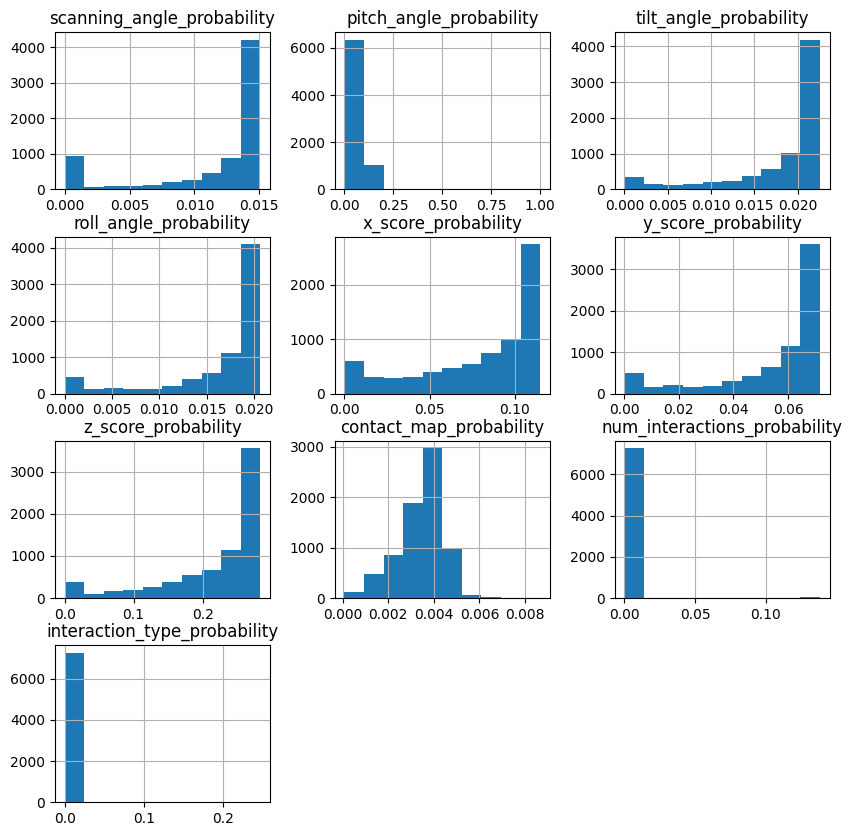

In [47]:
structure_scores[structure_probability_names].hist(figsize=(10, 10))
plt.show()

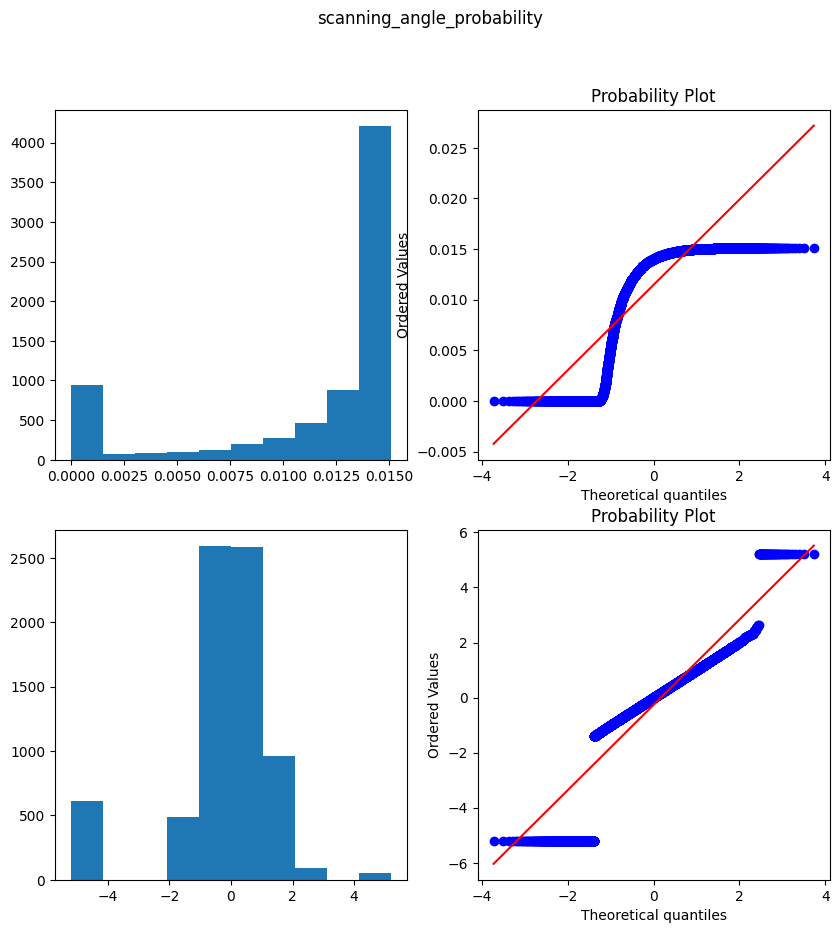

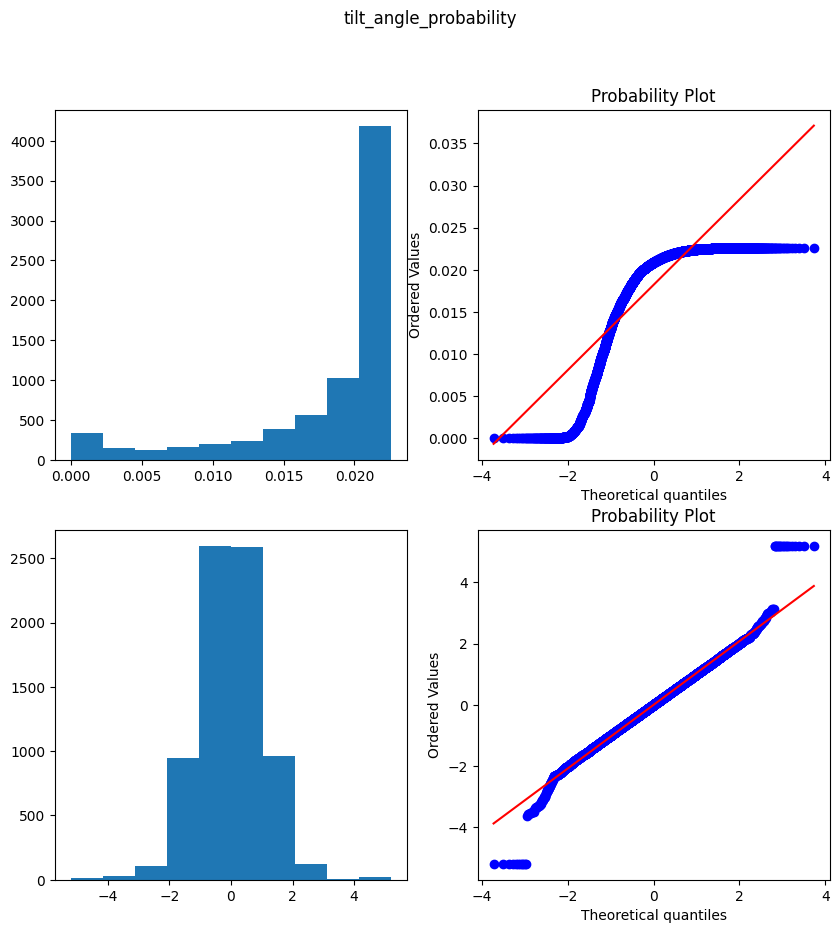

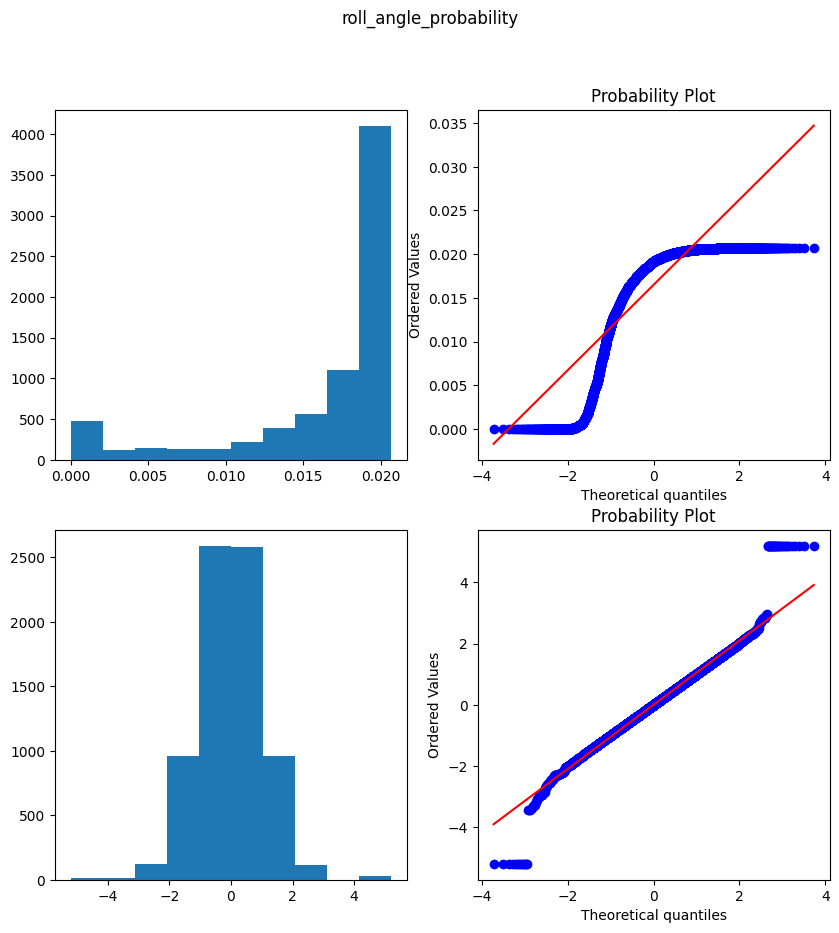

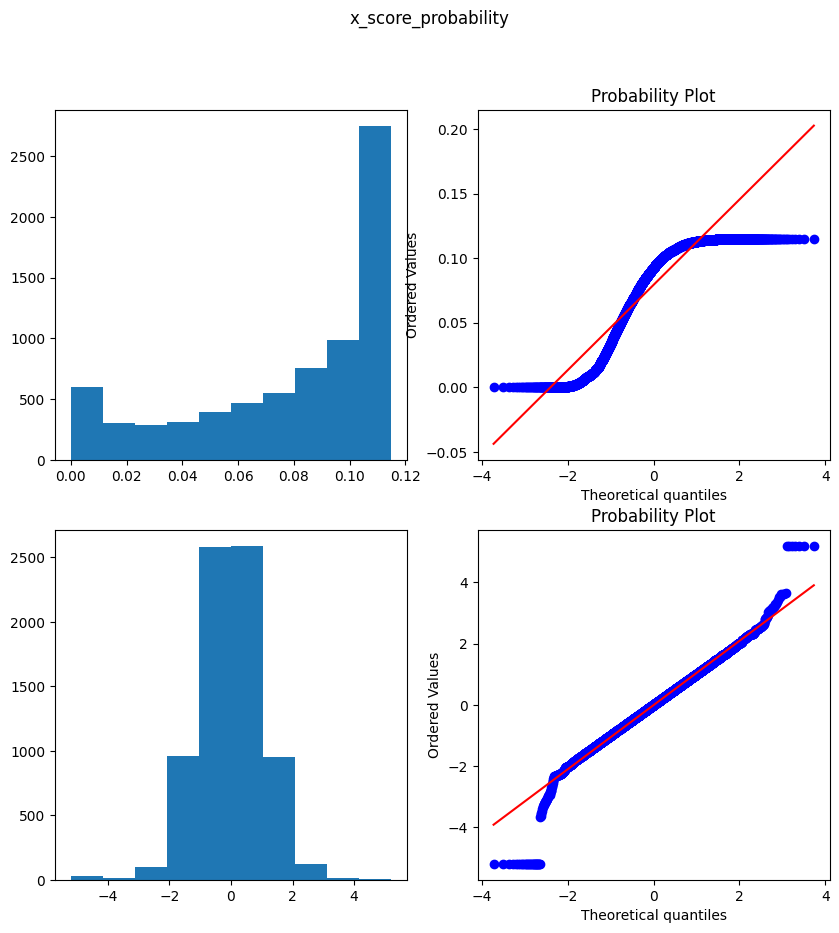

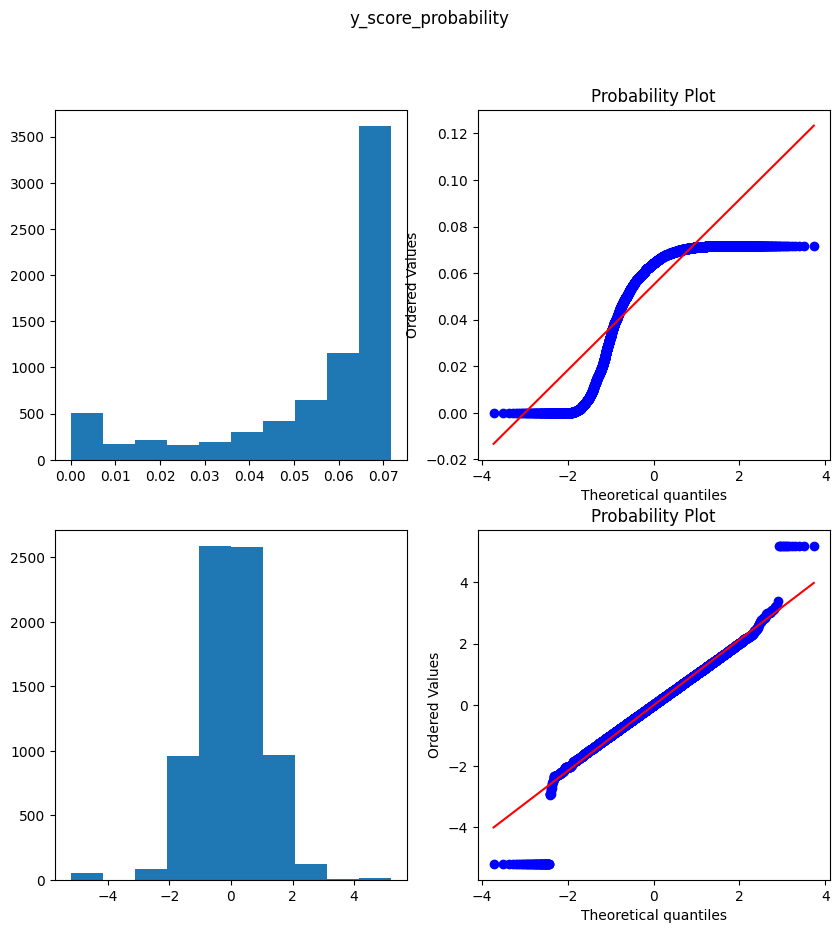

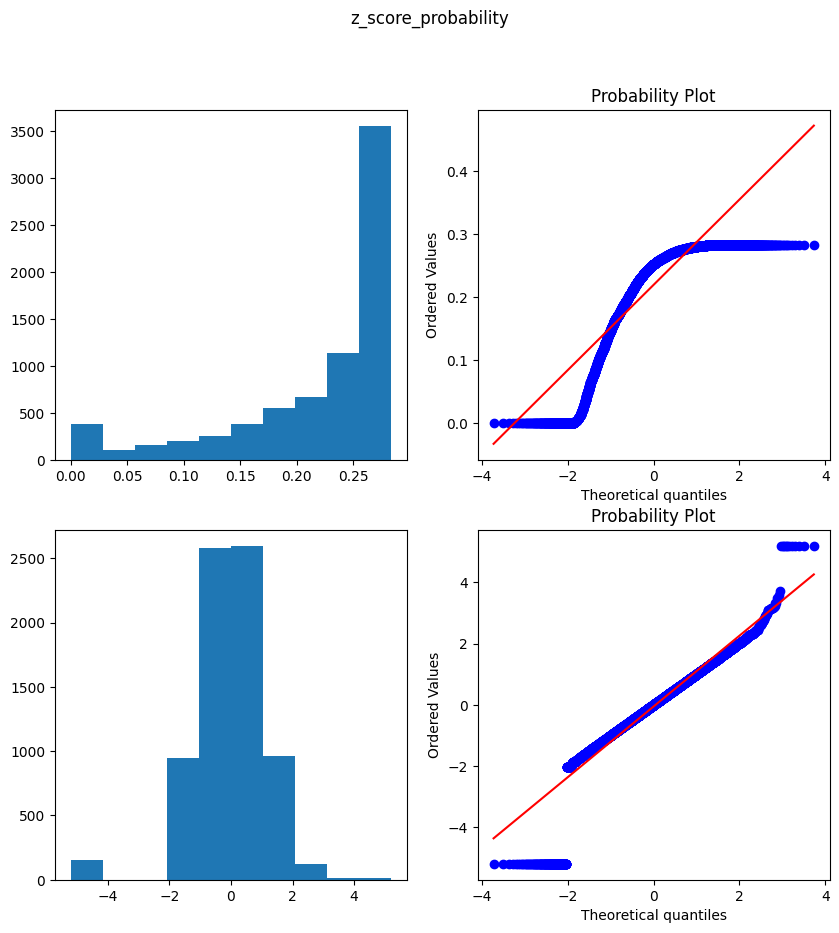

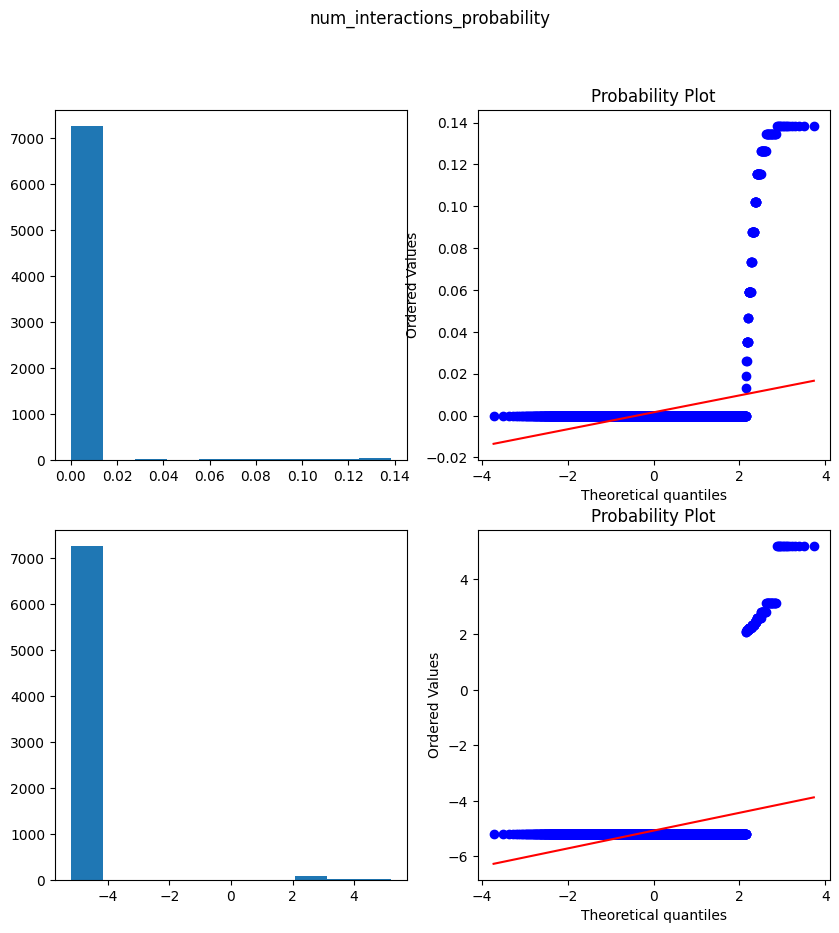

In [48]:
for selected_column in (
    'scanning_angle_probability',
    'tilt_angle_probability',
    'roll_angle_probability',
    'x_score_probability',
    'y_score_probability',
    'z_score_probability',
    'num_interactions_probability',
):
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

    fig.suptitle(selected_column)
    x = structure_scores[selected_column].to_numpy()

    qt = sklearn.preprocessing.QuantileTransformer(output_distribution='normal', n_quantiles=100)
    x_transformed = qt.fit_transform(x.reshape(-1, 1)).squeeze()

    structure_scores[selected_column + '_transformed'] = x_transformed

    axes[0, 0].hist(x)
    scipy.stats.probplot(x, dist=scipy.stats.norm, plot=axes[0, 1])

    axes[1, 0].hist(x_transformed)
    scipy.stats.probplot(x_transformed, dist=scipy.stats.norm, plot=axes[1, 1])

    structure_probability_names = [
        column if column != selected_column else selected_column + '_transformed'
        for column in structure_probability_names
    ]

    plt.show()

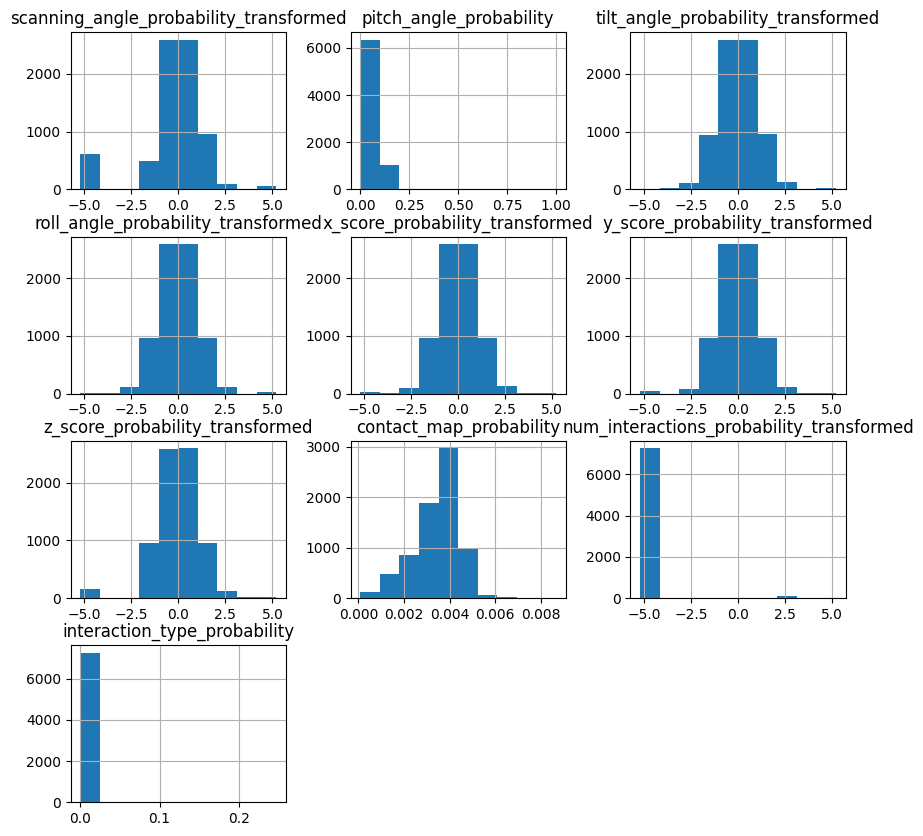

In [49]:
structure_scores[structure_probability_names].hist(figsize=(10, 10))
plt.show()

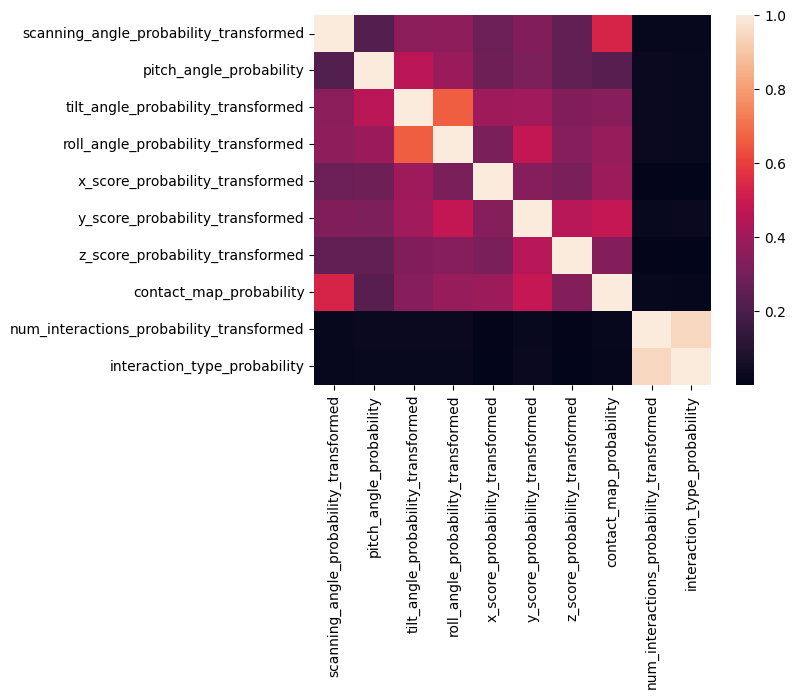

In [50]:
sns.heatmap(structure_scores[structure_probability_names].corr())

plt.show()

In [51]:
structure_probability_names = [
    column
    for column in structure_probability_names
    if column not in {'scanning_angle_probability_transformed', 'roll_angle_probability_transformed'}
]

## Regression analysis

In [52]:
regression_fits = defaultdict(list)

X = structure_scores[structure_probability_names]
X = sm.add_constant(X)

# PAE
pae_confidence_columns = sorted(structure_scores.filter(regex='pae').columns.tolist())
for confidence_column in pae_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    regression_fits['confidence_score'].append(confidence_column)
    regression_fits['confidence_type'].append('PAE')
    regression_fits['correlation_coef'].append(corr_coef)
    regression_fits['r_squared'].append(reg.rsquared)
    regression_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        regression_fits[key].append(value)

# (i)PTM
ptm_confidence_columns = sorted(structure_scores.filter(regex='ptm').columns.tolist())
for confidence_column in ptm_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    regression_fits['confidence_score'].append(confidence_column)
    regression_fits['confidence_type'].append('(i)PTM')
    regression_fits['correlation_coef'].append(corr_coef)
    regression_fits['r_squared'].append(reg.rsquared)
    regression_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        regression_fits[key].append(value)

# pLDDT
plddt_confidence_columns = sorted(structure_scores.filter(regex='plddt').columns.tolist())
for confidence_column in plddt_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    regression_fits['confidence_score'].append(confidence_column)
    regression_fits['confidence_type'].append('pLDDT')
    regression_fits['correlation_coef'].append(corr_coef)
    regression_fits['r_squared'].append(reg.rsquared)
    regression_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        regression_fits[key].append(value)

# IPSAE
ipsae_confidence_columns = sorted(structure_scores.filter(regex='ipsae').columns.tolist())
for confidence_column in ipsae_confidence_columns:
    y = structure_scores[confidence_column]
    y_max = structure_scores[confidence_column].max()

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
            corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    except scipy.stats.ConstantInputWarning:
        print('Skipping', confidence_column)
        continue

    regression_fits['confidence_score'].append(confidence_column)
    regression_fits['confidence_type'].append('IPSAE')
    regression_fits['correlation_coef'].append(corr_coef)
    regression_fits['r_squared'].append(reg.rsquared)
    regression_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: 1 - scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        regression_fits[key].append(value)

regression_fits = pd.DataFrame(regression_fits)
regression_fits = regression_fits.set_index('confidence_score')
regression_fits = regression_fits.sort_values('r_squared', ascending=False)

Skipping alpha_chain_alpha_chain_pae_min
Skipping antigen_chain_antigen_chain_pae_min
Skipping beta_chain_beta_chain_pae_min
Skipping mhc_chain_1_mhc_chain_1_pae_min
Skipping mhc_chain_2_mhc_chain_2_pae_min


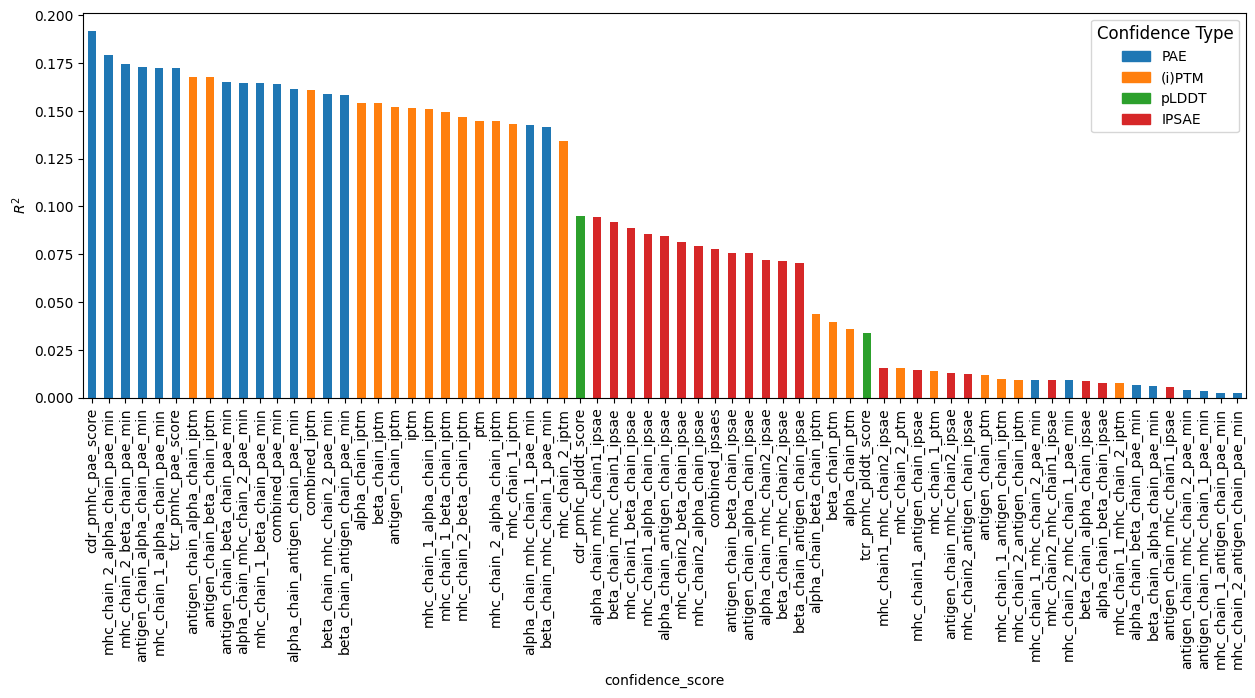

In [53]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
confidence_types = regression_fits['confidence_type'].unique()
colour_map = {c: default_colors[i % len(default_colors)] for i, c in enumerate(confidence_types)}
colours = regression_fits['confidence_type'].map(colour_map)

ax = regression_fits['r_squared'].plot.bar(figsize=(15, 5), color=colours)
ax.set_ylabel('$R^2$')

handles = [
    patches.Patch(color=colour_map[confidence_type], label=confidence_type) for confidence_type in confidence_types
]
ax.legend(handles=handles, title='Confidence Type', title_fontsize=12)

plt.show()

In [54]:
print('==============================================================================================')
print('Best results:', regression_fits.iloc[0].name, 'R^2:', f"{regression_fits.iloc[0]['r_squared']: .2f}")
print('==============================================================================================')
print('\n')

print(regression_fits.iloc[0].name)
print('==============================================================================================')
print(f"Pearson's correlation: {regression_fits.iloc[0]['correlation_coef']:.2f}")
print(regression_fits.iloc[0]['reg_summary'])
print('\n\n')

Best results: cdr_pmhc_pae_score R^2:  0.19


cdr_pmhc_pae_score
Pearson's correlation: 0.44
                            OLS Regression Results                            
Dep. Variable:     cdr_pmhc_pae_score   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.191
Method:                 Least Squares   F-statistic:                     218.4
Date:                Mon, 13 Oct 2025   Prob (F-statistic):               0.00
Time:                        12:40:46   Log-Likelihood:                -22488.
No. Observations:                7375   AIC:                         4.499e+04
Df Residuals:                    7366   BIC:                         4.506e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                               coef    std err          t      P>|t|      [0.025      0.975]
--------

In [55]:
coeficient_columns = ['parameter', 'standard_error', 't_stat', 'probability', 'significant']
coefficients = regression_fits.iloc[0][
    [name for name in regression_fits.iloc[0].index if type(name) is tuple and name[1] in coeficient_columns]
]

coefficients.index = pd.MultiIndex.from_tuples(coefficients.index)

coefficients = coefficients.unstack()  # noqa: PD010 unstack cleaner here
coefficients = coefficients[coeficient_columns]

coefficients

,parameter,standard_error,t_stat,probability,significant
contact_map_probability,-1196.185639,70.998608,-16.848015,0.0,True
interaction_type_probability,1.688588,9.823837,0.171887,0.568234,False
num_interactions_probability_transformed,-0.181371,0.186346,-0.973302,0.165218,False
pitch_angle_probability,-2.331722,1.592204,-1.464461,0.071555,False
tilt_angle_probability_transformed,-0.252224,0.070126,-3.596746,0.000162,True
x_score_probability_transformed,-0.480723,0.065047,-7.390409,0.0,True
y_score_probability_transformed,-0.707949,0.068817,-10.28735,0.0,True
z_score_probability_transformed,-0.463123,0.056715,-8.165822,0.0,True


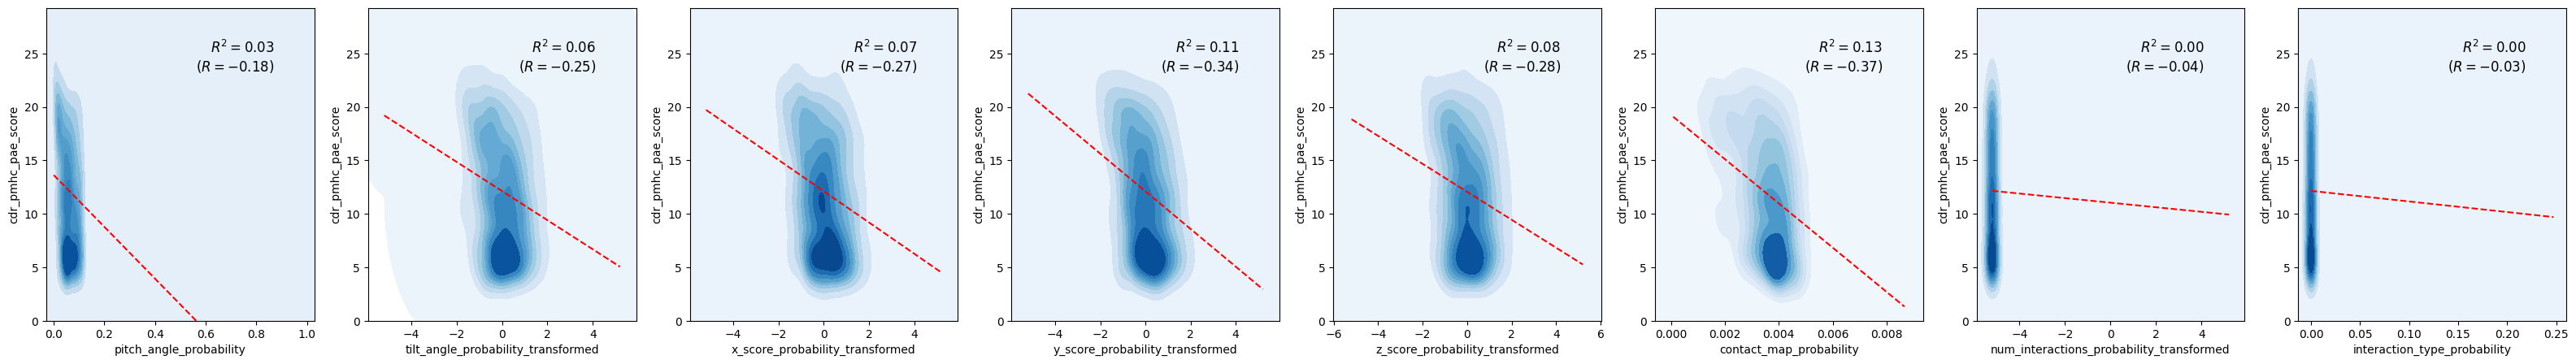

In [56]:
fig, axes = plt.subplots(1, len(structure_probability_names), figsize=(5 * len(structure_probability_names), 5))

y = structure_scores[regression_fits.iloc[0].name]
y_max = structure_scores[regression_fits.iloc[0].name].max()

axes[0].set_ylabel(regression_fits.iloc[0].name)

for i, column in enumerate(structure_probability_names):
    x = structure_scores[column]
    sns.kdeplot(x=x, y=y, cmap='Blues', fill=True, thresh=0, levels=10, ax=axes[i])

    reg = scipy.stats.linregress(x, y)
    x = np.linspace(x.min(), x.max())
    y_pred = reg.slope * x + reg.intercept

    axes[i].plot(x, y_pred, 'r--')
    axes[i].text(
        0.85,
        0.90,
        f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
        transform=axes[i].transAxes,
        horizontalalignment='right',
        verticalalignment='top',
        fontsize=12,
    )

    axes[i].set_xlabel(column)
    axes[i].set_ylim(0, y_max)

plt.show()

## Analysing results robustness

### Removing outliers using Mahalanobis distance

In [57]:
data = structure_scores[[*structure_probability_names, 'cdr_pmhc_pae_score']]

centre = data.mean(axis=0)
centred_data = data.to_numpy() - centre.to_numpy().reshape(1, -1)

covariance = np.cov(data, rowvar=False)
covariance_inv = np.linalg.inv(covariance)

distances = np.dot(np.dot(centred_data, covariance_inv), centred_data.T).diagonal()

In [58]:
data_no_outliers = data.loc[distances <= scipy.stats.chi2.ppf(0.95, data.shape[1])]
data_outliers = data.loc[distances > scipy.stats.chi2.ppf(0.95, data.shape[1])]

In [59]:
def check_constant_column(column: pd.Series) -> bool:
    return (column.iloc[0] == column).all()


contstant_columns_to_drop = [
    column_name for column_name in data_no_outliers.columns if check_constant_column(data_no_outliers[column_name])
]
print('Dropping constant columns', contstant_columns_to_drop)
data_no_outliers = data_no_outliers[
    [column_name for column_name in data_no_outliers.columns if column_name not in contstant_columns_to_drop]
]

no_outliers_structure_columns = [
    column_name for column_name in data_no_outliers.columns if column_name != 'cdr_pmhc_pae_score'
]

Dropping constant columns ['num_interactions_probability_transformed', 'interaction_type_probability']


In [60]:
X = data_no_outliers[no_outliers_structure_columns]
X = sm.add_constant(X, has_constant='raise')
y = data_no_outliers['cdr_pmhc_pae_score']

In [61]:
model = sm.OLS(y, X)
reg = model.fit()
pred_y = reg.fittedvalues

with warnings.catch_warnings():
    warnings.simplefilter('error', scipy.stats.ConstantInputWarning)
    corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

print(reg.summary())

coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
coefficients.columns = ['parameter', 'standard_error']

coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

coefficients['probability'] = coefficients['t_stat'].apply(
    lambda t_stat, dof=reg.df_resid: scipy.stats.t.cdf(t_stat, df=dof)
)
coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

coefficients

                            OLS Regression Results                            
Dep. Variable:     cdr_pmhc_pae_score   R-squared:                       0.148
Model:                            OLS   Adj. R-squared:                  0.148
Method:                 Least Squares   F-statistic:                     201.2
Date:                Mon, 13 Oct 2025   Prob (F-statistic):          2.91e-237
Time:                        12:41:17   Log-Likelihood:                -21124.
No. Observations:                6940   AIC:                         4.226e+04
Df Residuals:                    6933   BIC:                         4.231e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
cons

,parameter,standard_error,t_stat,probability,significant
pitch_angle_probability,-4.407280,2.556884,-1.723692,4.240402e-02,True
tilt_angle_probability_transformed,-0.111060,0.083791,-1.325434,9.253543e-02,False
x_score_probability_transformed,-0.458801,0.073436,-6.247602,2.207380e-10,True
y_score_probability_transformed,-0.611986,0.078743,-7.771974,4.422557e-15,True
z_score_probability_transformed,-0.227526,0.070514,-3.226691,6.290634e-04,True
contact_map_probability,-1440.724772,79.889756,-18.033911,2.181379e-71,True


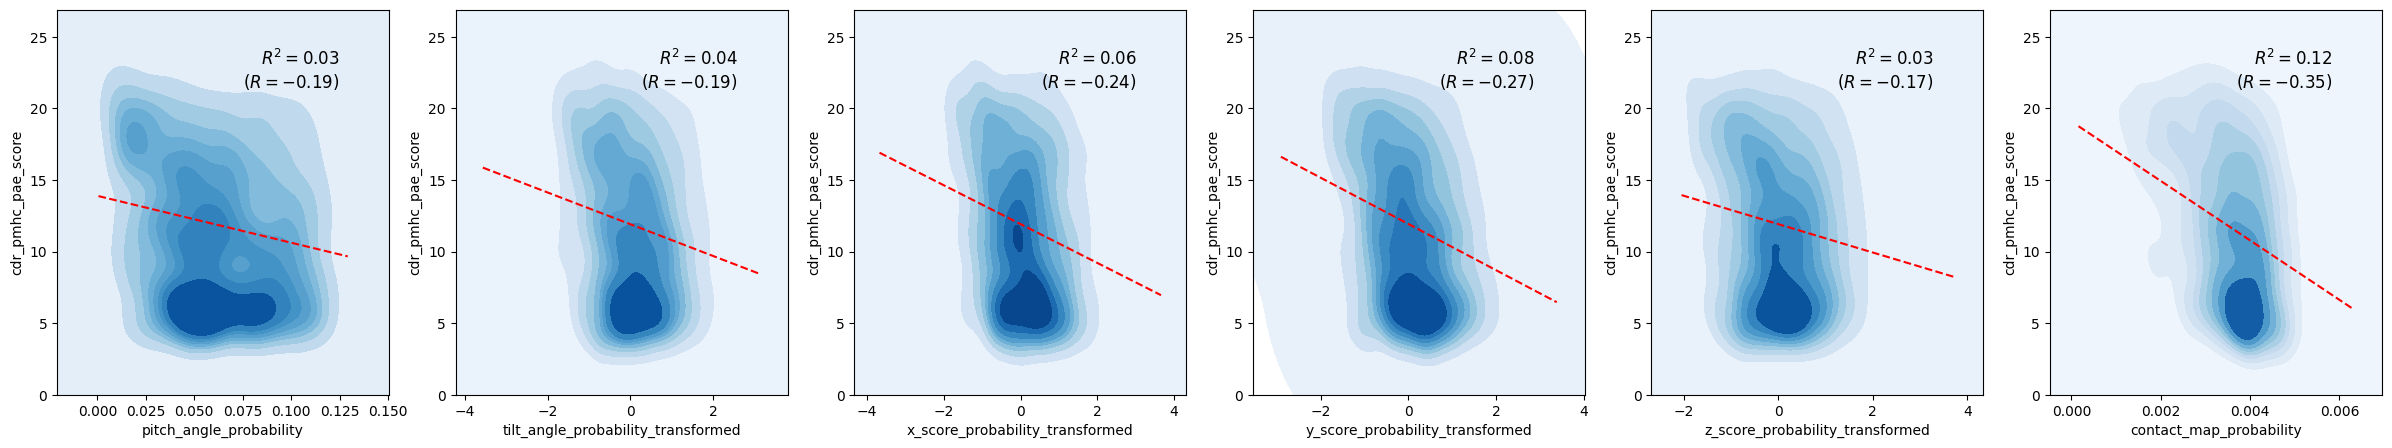

In [62]:
fig, axes = plt.subplots(1, len(no_outliers_structure_columns), figsize=(5 * len(no_outliers_structure_columns), 5))

y_max = y.max()

axes[0].set_ylabel(regression_fits.iloc[0].name)

for i, column in enumerate(no_outliers_structure_columns):
    x = X[column]
    sns.kdeplot(x=x, y=y, cmap='Blues', fill=True, thresh=0, levels=10, ax=axes[i], warn_singular=False)

    try:
        reg = scipy.stats.linregress(x, y)

    except ValueError:
        pass

    else:
        x = np.linspace(x.min(), x.max())
        y_pred = reg.slope * x + reg.intercept

        axes[i].plot(x, y_pred, 'r--')
        axes[i].text(
            0.85,
            0.90,
            f'$R^2={reg.rvalue**2: .2f}$\n($R={reg.rvalue: .2f}$)',
            transform=axes[i].transAxes,
            horizontalalignment='right',
            verticalalignment='top',
            fontsize=12,
        )

    axes[i].set_xlabel(column)
    axes[i].set_ylim(0, y_max)

plt.show()

### Bootstrapping results

In [63]:
bootstrap_fits = defaultdict(list)

num_samples = 100
sample_size = 1_000
rng = np.random.default_rng(123)

for _ in range(num_samples):
    sample = data_no_outliers.sample(sample_size, random_state=rng)

    X = sample[no_outliers_structure_columns]
    X = sm.add_constant(X)
    y = sample['cdr_pmhc_pae_score']

    model = sm.OLS(y, X)
    reg = model.fit()
    pred_y = reg.fittedvalues

    corr_coef, _ = scipy.stats.pearsonr(y, pred_y)

    bootstrap_fits['correlation_coef'].append(corr_coef)
    bootstrap_fits['r_squared'].append(reg.rsquared)
    bootstrap_fits['reg_summary'].append(str(reg.summary()))

    coefficients = pd.concat([reg.params[1:], reg.bse[1:]], axis=1)
    coefficients.columns = ['parameter', 'standard_error']

    coefficients['t_stat'] = coefficients['parameter'] / coefficients['standard_error']

    coefficients['probability'] = coefficients['t_stat'].apply(
        lambda t_stat, dof=reg.df_resid: scipy.stats.t.cdf(t_stat, df=dof)
    )
    coefficients['significant'] = coefficients['probability'] < SIGNIFICANCE_LEVEL

    for key, value in coefficients.stack().to_dict().items():  # noqa: PD013 stack cleaner here
        bootstrap_fits[key].append(value)

bootstrap_fits = pd.DataFrame(bootstrap_fits)

In [64]:
bootstrap_significance = bootstrap_fits[
    [
        column_name
        for column_name in bootstrap_fits.columns
        if type(column_name) is tuple and column_name[1] == 'significant'
    ]
]

bootstrap_significance.columns = [column_name[0] for column_name in bootstrap_significance.columns]
bootstrap_significance = bootstrap_significance.melt(
    value_vars=bootstrap_significance.columns, var_name='property', value_name='significant'
)

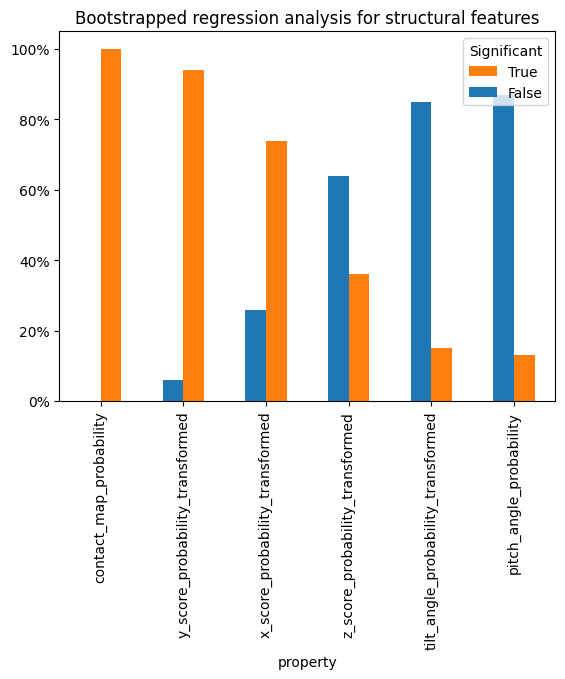

In [65]:
ax = (
    bootstrap_significance.map(str)
    .value_counts()
    .reset_index()
    .pivot_table(index='property', columns='significant', values='count')
    .fillna(0)
    .map(int)
    .sort_values('True', ascending=False)
    .plot.bar()
)

ax.yaxis.set_major_formatter(PercentFormatter())

handles, labels = ax.get_legend_handles_labels()
labels, handles = zip(*sorted(zip(labels, handles, strict=True), key=lambda t: t[0], reverse=True), strict=True)
ax.legend(handles, labels, title='Significant', loc='upper right')

ax.set_title('Bootstrapped regression analysis for structural features')

plt.show()